## Order books and trades

A snapshot of the book of Bitcoin's perpetual at each of the six exchanges, as depth around
its mid, and each venue's latest trades by size and side. Both are taken at the moment the
notebook runs, so no two runs show the same numbers.

In [1]:
import exchange_router
import matplotlib.pyplot
import matplotlib.ticker
import numpy
import pandas

matplotlib.pyplot.style.use(style="../oceano.mplstyle")

print(f"exchange-router {exchange_router.__version__}")

exchange-router 3.0.1


### The books and the trades

Each venue's book to the deepest the router serves for it, and its most recent trades, as
many as it serves in one call: a thousand at Binance and Bybit, a hundred at OKX, Kraken and
KuCoin, ten at Hyperliquid.

In [2]:
SYMBOLS = {"binance": "BTCUSDT", "bybit": "BTCUSDT", "okx": "BTCUSDT",
           "kraken": "XBTUSD", "kucoin": "XBTUSDT", "hyperliquid": "BTCUSDC"}
LATEST  = {"binance": 1_000, "bybit": 1_000, "okx": 100, "kraken": 100, "kucoin": 100,
           "hyperliquid": 10}

books, trades = {}, {}
with exchange_router.Router.local(exchanges=list(SYMBOLS)) as router:
    for exchange, symbol in SYMBOLS.items():
        offered = router.get_capabilities(exchange=exchange)["markets"]["linear"]
        books[exchange] = router.get_orderbook(exchange=exchange, market_type="linear",
                                               symbol=symbol,
                                               depth=offered["orderbook"]["max_depth"])
        trades[exchange] = router.get_trades(exchange=exchange, market_type="linear",
                                             symbol=symbol, limit=LATEST[exchange])

books["okx"].head(n=4)

,side,price,qty
0,bid,77825.6,16.9896
1,bid,77825.5,0.0610
2,bid,77825.4,0.0002
3,bid,77825.3,0.0001


### The top of each book

A book is a frame of `side`, `price` and `qty`, the bids best first, then the asks. From it
the spread, how far from the mid the levels served reach, and the dollars resting within ten
basis points of the mid on each side, which a market order of that size would take.

In [3]:
tops = {}
for exchange, book in books.items():
    bid  = book.loc[book.side == "bid", "price"].max()
    ask  = book.loc[book.side == "ask", "price"].min()
    mid  = (bid + ask) / 2.0
    away = (book.price - mid).abs() / mid * 10_000
    near = away <= 10.0
    held = book.price * book.qty / 1e6
    tops[exchange] = {"levels a side": len(book) // 2, "mid": mid,
                      "spread, bps": (ask - bid) / mid * 10_000,
                      "reaches, bps": away.max(),
                      "bids within 10 bps, $m": held[near & (book.side == "bid")].sum(),
                      "asks within 10 bps, $m": held[near & (book.side == "ask")].sum()}

pandas.DataFrame(tops).T.astype({"levels a side": int}).round(decimals=2)

,levels a side,mid,"spread, bps","reaches, bps","bids within 10 bps, $m","asks within 10 bps, $m"
binance,1000,77827.55,0.01,18.17,21.44,24.06
bybit,500,77824.65,0.01,11.66,23.28,25.60
okx,400,77825.65,0.01,6.97,16.44,15.09
kraken,500,77758.50,0.13,359.00,18.39,16.87
kucoin,100,77820.05,0.01,7.82,4.47,3.68
hyperliquid,20,77823.50,0.13,2.51,4.63,5.51


### Depth around the mid

The dollars resting from the mid out to each price, the bids to the left and the asks to
the right, on a log scale. A line ends where the levels the venue served end.

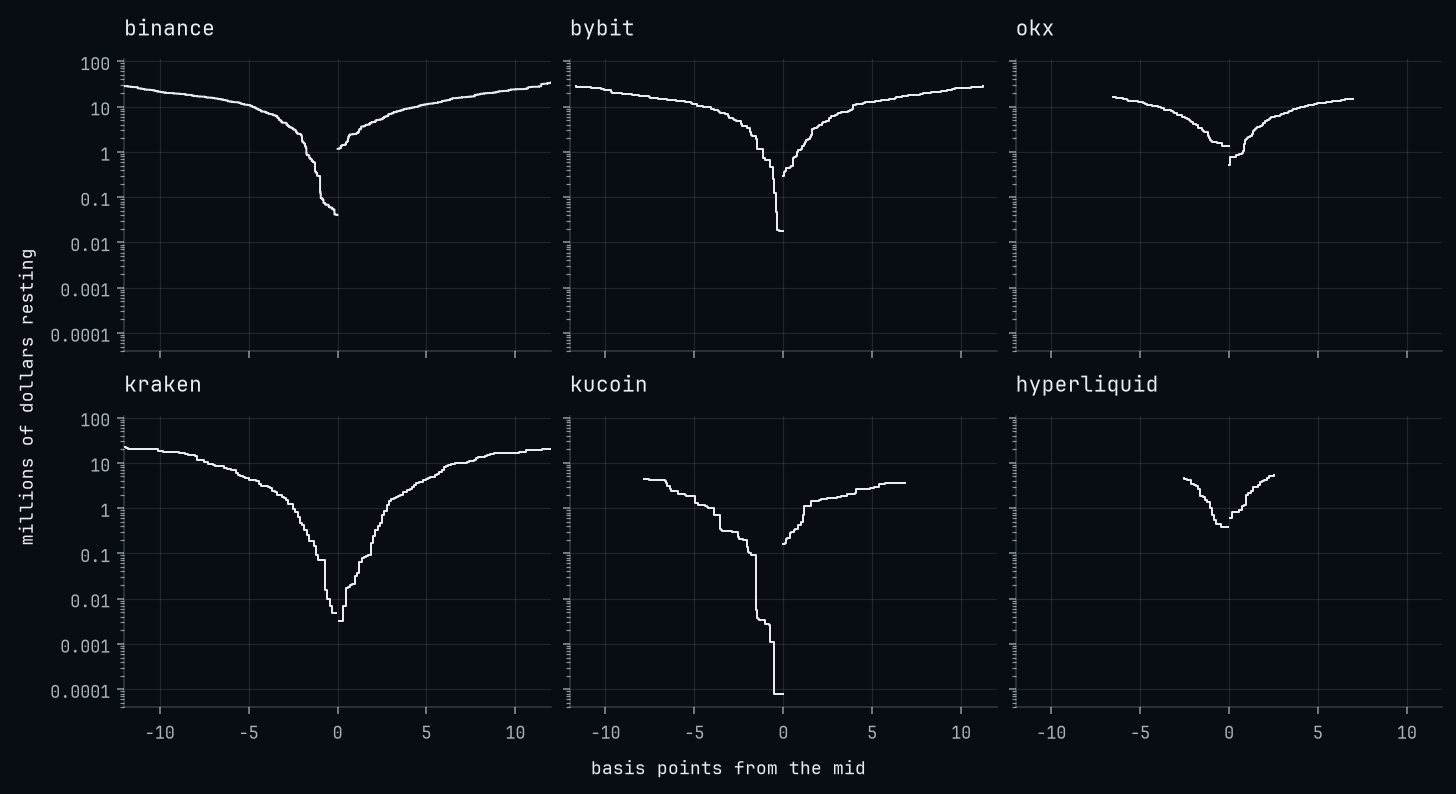

In [4]:
figure, grid = matplotlib.pyplot.subplots(nrows=2, ncols=3, sharex=True, sharey=True,
                                          figsize=(10.0, 5.4))

for axes, (exchange, book) in zip(grid.flat, books.items()):
    mid = tops[exchange]["mid"]
    for side, sign in (("bid", -1.0), ("ask", 1.0)):
        levels = book[book.side == side]
        axes.step(sign * (levels.price - mid).abs() / mid * 10_000,
                  (levels.price * levels.qty).cumsum() / 1e6, where="post", color="C0",
                  linestyle="-", linewidth=1.0)
    axes.set_title(label=exchange)
    axes.set_yscale(value="log")
    axes.yaxis.set_major_formatter(matplotlib.ticker.StrMethodFormatter(fmt="{x:g}"))
    axes.set_xlim(left=-12.0, right=12.0)

figure.supxlabel(t="basis points from the mid", fontsize=9)
figure.supylabel(t="millions of dollars resting", fontsize=9)
matplotlib.pyplot.show()

### The latest trades

What each venue's last call held: how many seconds of trading, the share of dollars the
buyers took, and the trades' sizes. `side` is the taker's.

In [5]:
pandas.DataFrame({exchange: {"trades": len(frame),
                             "seconds": (frame.index[-1] - frame.index[0]).total_seconds(),
                             "bought, % of $": frame.qty_usd[frame.side == "buy"].sum()
                                               / frame.qty_usd.sum() * 100,
                             "median $": frame.qty_usd.median(),
                             "largest $": frame.qty_usd.max()}
                  for exchange, frame in trades.items()}).T.astype({"trades": int}).round(
    decimals=1)

,trades,seconds,"bought, % of $",median $,largest $
binance,1000,147.2,20.9,155.7,82282.2
bybit,1000,196.7,73.9,155.7,1283893.0
okx,100,16.7,1.2,38.9,89102.5
kraken,100,94.5,50.5,373.3,2185.1
kucoin,100,777.2,49.0,155.5,7698.8
hyperliquid,10,13.7,41.2,108.6,1190.7


### Each trade by size and side

Every trade fetched, one dot each on a log scale of dollars, buys filled and sells hollow,
spread up and down its row so the dots do not cover one another.

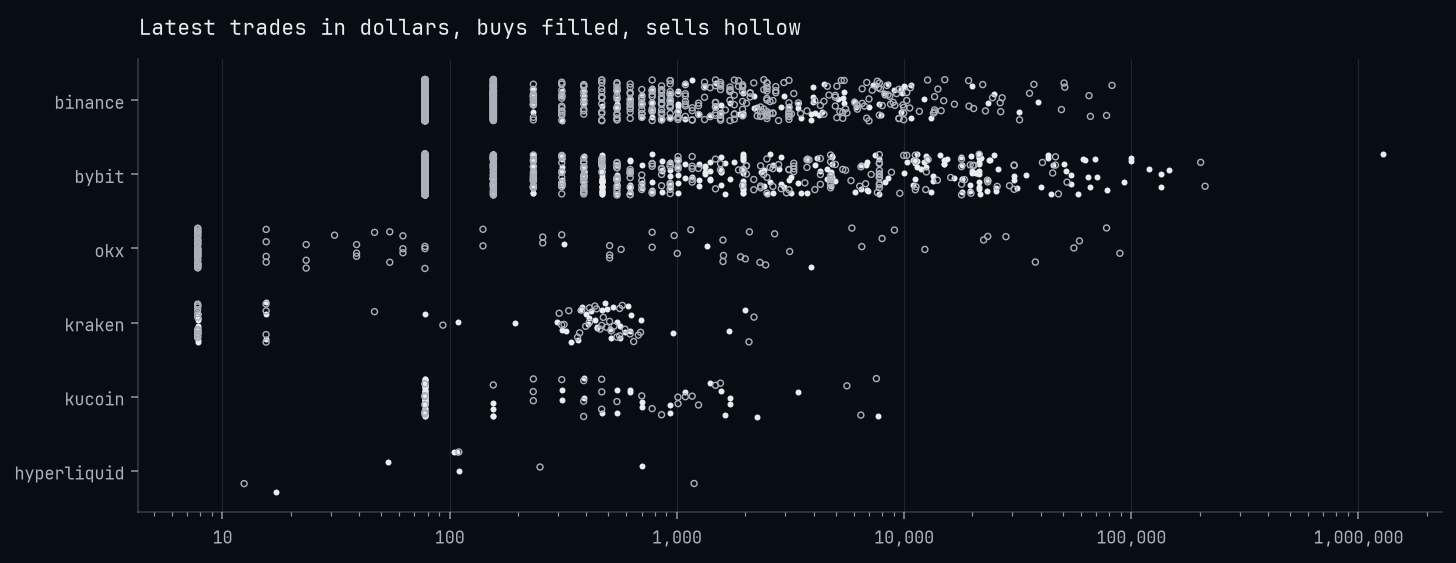

In [6]:
figure, axes = matplotlib.pyplot.subplots(figsize=(10.0, 3.8))

for row, (exchange, frame) in enumerate(trades.items()):
    spread = numpy.random.default_rng(seed=row).uniform(low=-0.28, high=0.28, size=len(frame))
    bought = (frame.side == "buy").to_numpy()
    axes.scatter(frame.qty_usd[bought], row + spread[bought], s=9.0, color="C0",
                 linewidths=0.0)
    axes.scatter(frame.qty_usd[~bought], row + spread[~bought], s=9.0, facecolors="none",
                 edgecolors="C1", linewidths=0.7)

axes.set_xscale(value="log")
axes.xaxis.set_major_formatter(matplotlib.ticker.StrMethodFormatter(fmt="{x:,.0f}"))
axes.set_yticks(ticks=range(len(trades)), labels=list(trades))
axes.invert_yaxis()
axes.grid(axis="y", visible=False)
axes.set_title(label="Latest trades in dollars, buys filled, sells hollow")
matplotlib.pyplot.show()